# Design rainfall at Toronto Pearson

Inspect ECCC's published **15-minute, 1-hour and 24-hour rainfall intensities**, compare the SDK's fitted curves with those values, and audit changes between releases **3.20 and 3.40**. Export the same results through the [paired pipeline](../pipelines/eccc_idf_pipeline.py).

Use Python 3.12+ with a local crc-sdk checkout and its geometry extra. From crc-docs, link it with `uv pip install --python .venv/bin/python --no-deps --editable ../crc-sdk`, then launch Jupyter with `uv run --no-sync --with matplotlib jupyter lab`. This uses the local SDK without changing the repository's dependency declarations or lockfile. No API key is needed.

The first current-release request transfers roughly **149 MB** for Ontario's nested provincial bundle; the national archive is about 698 MB. Only small checksummed station TXT files remain in the cache. Later durations and offline replay reuse them. The archived release permits small station-level byte-range reads.

The example uses ECCC climate ID **6158731**, not the similarly named NOAA station ID. These are historical station estimates, without climate adjustment or spatial interpolation.

In [1]:
import importlib.util
import os
from pathlib import Path
import sys

REQUIREMENTS = ["duckdb>=1.4.5,<2", "plotly>=6", "pandas>=2", "nbformat>=5", "matplotlib>=3"]
# Install these notebook dependencies in your environment if they are missing.
missing = [name for name in ("plotly", "duckdb", "crc_sdk", "pandas", "matplotlib")
           if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f"Install notebook dependencies and link crc-sdk first: {missing}")
from crc_sdk.workflows import HazardDataset
if not hasattr(HazardDataset, "eccc_idf"):
    raise RuntimeError("Link your local crc-sdk checkout and restart the kernel.")
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
print("Local ECCC IDF adapter ready")

Local ECCC IDF adapter ready


In [2]:
import base64
import io
import json
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "pipelines/eccc_idf_pipeline.py").is_file():
    raise RuntimeError("Run from crc-docs or its notebooks directory.")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from pipelines.eccc_idf_pipeline import run

def show_with_preview(figure, preview):
    # A browser-free PNG fallback keeps saved charts visible in static viewers.
    buffer = io.BytesIO()
    preview.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    plt.close(preview)
    display({
        "application/vnd.plotly.v1+json": json.loads(figure.to_json()),
        "image/png": base64.b64encode(buffer.getvalue()).decode(),
    }, raw=True)

## Select a duration and station

Plans are immutable and make no network requests until execution. Use explicit climate IDs when you know the station. For regional comparisons, set `AREAS` below to a list of WGS84 boxes: `.for_areas(AREAS)` selects their **union within the chosen province**. `.for_area(bounds)` is the single-box shorthand. Duplicate or overlapping boxes never duplicate stations or archive requests; locations between disjoint boxes are excluded.

Area selection replaces explicit IDs and reads the province's station files. Prefetch that selection online before replaying it offline; a cache containing only explicitly requested stations may be incomplete. H3 indexes the selected points without interpolating a rainfall surface.

Each duration is a distinct hazard, for example `RainfallIntensity/1h`, in **mm/h**. Each station's inclusive record midpoint becomes its horizon. Stations with different record windows retain different horizons; they are not one common baseline.

In [3]:
PROVINCE = "ON"
STATIONS = ("6158731",)
AREAS = None
# For an Ontario area union, replace None with:
# [(-79.65, 43.65, -79.61, 43.70), (-75.70, 45.30, -75.65, 45.35)]
DURATIONS = ("15min", "1h", "24h")
VERSION, PREVIOUS = "3.40", "3.20"
OUTPUT = Path("pipeline_output/eccc_idf")
CACHE = OUTPUT / "cache"
selection = HazardDataset.eccc_idf("1h", province=PROVINCE, version=VERSION)
selection = selection.for_areas(AREAS) if AREAS is not None else selection.for_stations(STATIONS)
plan = selection.cache(CACHE, mode="reuse")
print(plan.explain())

{
  "provider": "eccc-idf",
  "version": "3.40",
  "province": "ON",
  "stations": [
    "6158731"
  ],
  "areas": [],
  "duration": "1h",
  "url": "https://collaboration.cmc.ec.gc.ca/cmc/climate/Engineer_Climate/IDF/idf_v3-40_2025-12-5.zip",
  "hazard_name": "RainfallIntensity/1h",
  "unit": "mm/h",
  "spatial_support": "station point; H3 index only; no interpolation",
  "horizon": "each station's inclusive record midpoint",
  "acquisition": "provincial bundle",
  "licence": "OGL-Canada-2.0",
  "attribution": "Derived from Environment and Climate Change Canada rainfall IDF. Contains information licensed under the Open Government Licence \u2013 Canada.",
  "cache": {
    "mode": "reuse",
    "directory": "pipeline_output/eccc_idf/cache"
  }
}


## Acquire once and inspect the source

Table 2b's central estimates and 95% confidence half-widths are read separately. The header supplies the actual return-period labels: release 3.40 adds **200 years**, whereas 3.20 ends at 100 years. Annual maxima, rainfall amount tables and interpolation coefficients are not used as fitting samples.

The pipeline writes canonical Parquet curves and diagnostics per release/duration, an inspection table of official rates, a long comparison table, and a JSON summary. Set `MODE = "offline"` after a successful run to verify that the same cached bytes reproduce the analysis.

In [4]:
MODE = "reuse"
summary = run(
    OUTPUT, province=PROVINCE, stations=None if AREAS is not None else STATIONS,
    areas=AREAS, durations=DURATIONS,
    version=VERSION, compare_version=PREVIOUS, cache_mode=MODE, cache=CACHE,
)
display(pd.Series(summary).to_frame("value"))
source = pq.read_table(OUTPUT / "published_source_curves.parquet").to_pandas()
SELECTED_STATIONS = tuple(sorted(source.station.unique()))
display(source[["station", "name", "source_version", "duration_minutes",
                "start_year", "end_year", "record_years", "latitude", "longitude"]])

{
  "provider": "eccc-idf",
  "version": "3.40",
  "province": "ON",
  "stations": [
    "6158731"
  ],
  "areas": [],
  "duration": "15min",
  "url": "https://collaboration.cmc.ec.gc.ca/cmc/climate/Engineer_Climate/IDF/idf_v3-40_2025-12-5.zip",
  "hazard_name": "RainfallIntensity/15min",
  "unit": "mm/h",
  "spatial_support": "station point; H3 index only; no interpolation",
  "horizon": "each station's inclusive record midpoint",
  "acquisition": "provincial bundle",
  "licence": "OGL-Canada-2.0",
  "attribution": "Derived from Environment and Climate Change Canada rainfall IDF. Contains information licensed under the Open Government Licence \u2013 Canada.",
  "cache": {
    "mode": "reuse",
    "directory": "pipeline_output/eccc_idf/cache"
  }
}


{
  "provider": "eccc-idf",
  "version": "3.20",
  "province": "ON",
  "stations": [
    "6158731"
  ],
  "areas": [],
  "duration": "15min",
  "url": "https://collaboration.cmc.ec.gc.ca/cmc/climate/Engineer_Climate/IDF/IDF_archive/idf_v-3.20_2021_3_26/IDF_Files_Fichiers/IDF_v-3.20_2021_03_26_ON.zip",
  "hazard_name": "RainfallIntensity/15min",
  "unit": "mm/h",
  "spatial_support": "station point; H3 index only; no interpolation",
  "horizon": "each station's inclusive record midpoint",
  "acquisition": "station TXT byte ranges",
  "licence": "OGL-Canada-2.0",
  "attribution": "Derived from Environment and Climate Change Canada rainfall IDF. Contains information licensed under the Open Government Licence \u2013 Canada.",
  "cache": {
    "mode": "reuse",
    "directory": "pipeline_output/eccc_idf/cache"
  }
}


,value
province,ON
stations,[6158731]
areas,()
durations,"[15min, 1h, 24h]"
acquisition,"[{'version': '3.40', 'cache_hits': 1, 'cache_m..."
rate_rows,39
comparison_rows,18
maximum_absolute_fit_residual_mm_h,0.051932
interpretation,Published central rates and 95% confidence hal...


,station,name,source_version,duration_minutes,start_year,end_year,record_years,latitude,longitude
0,6158731,TORONTO INTL A,3.40,15,1950,2017,64,43.666667,-79.633333
1,6158731,TORONTO INTL A,3.40,60,1950,2017,65,43.666667,-79.633333
2,6158731,TORONTO INTL A,3.40,1440,1950,2017,65,43.666667,-79.633333
3,6158731,TORONTO INTL A,3.20,15,1950,2017,64,43.683333,-79.633333
4,6158731,TORONTO INTL A,3.20,60,1950,2017,65,43.683333,-79.633333
5,6158731,TORONTO INTL A,3.20,1440,1950,2017,65,43.683333,-79.633333


## Published central estimates and fitted curves

The canonicalizer fits Gumbel quantiles using `p = 1 - 1/T`, with an absolute residual gate of **0.15 mm/h** at the published knots. This is an SDK refit, not ECCC's official method-of-moments result. Inspect residuals before using the fit at additional return periods.

Error bars below are **ECCC's published 95% confidence half-widths**, not errors in the refit, prediction intervals for an individual storm, or probabilities of future climate scenarios.

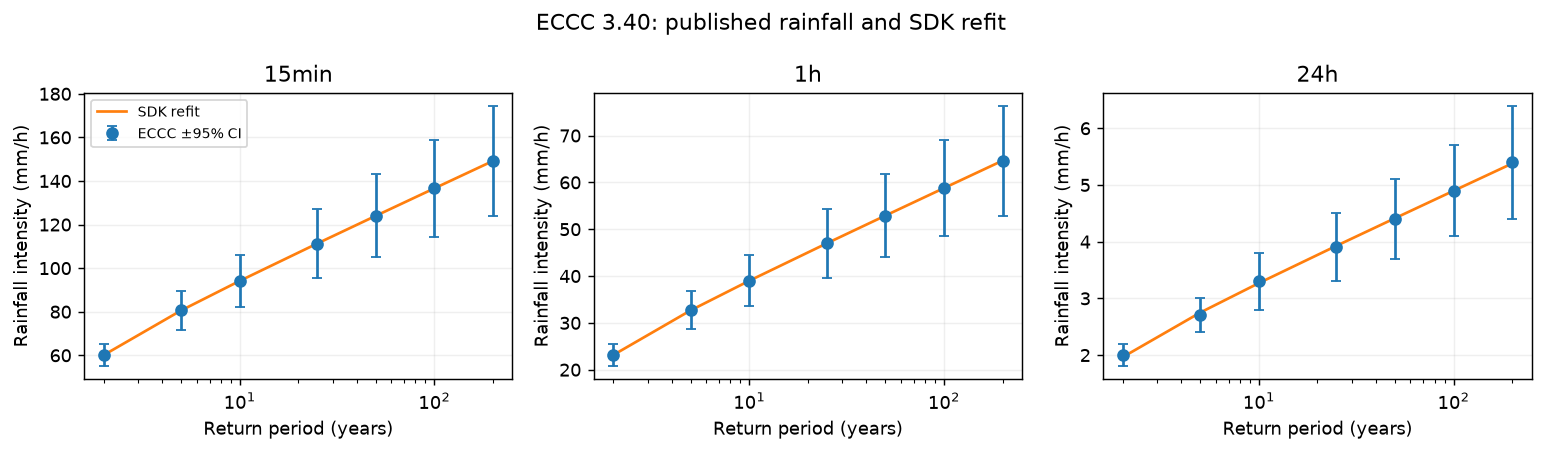

,station,duration,return_period_years,published_mm_h,fitted_mm_h,fit_residual_mm_h,beyond_record_length
0,6158731,15min,2.0,60.1,60.094659,-0.005341,False
1,6158731,15min,5.0,80.6,80.580642,-0.019358,False
2,6158731,15min,10.0,94.1,94.144145,0.044145,False
3,6158731,15min,25.0,111.3,111.281667,-0.018333,False
4,6158731,15min,50.0,124.0,123.995260,-0.004740,False
5,6158731,15min,100.0,136.6,136.614978,0.014978,True
6,6158731,15min,200.0,149.2,149.188648,-0.011352,True
7,6158731,1h,2.0,23.1,23.133227,0.033227,False
8,6158731,1h,5.0,32.7,32.676443,-0.023557,False
9,6158731,1h,10.0,39.0,38.994883,-0.005117,False


In [5]:
rates = pq.read_table(OUTPUT / "rainfall_rates.parquet").to_pandas()
current = rates[rates.version == VERSION].copy()
fig = make_subplots(rows=1, cols=len(DURATIONS), subplot_titles=list(DURATIONS))
for col, duration in enumerate(DURATIONS, 1):
    for station in SELECTED_STATIONS:
        view = current[(current.duration == duration) & (current.station == station)]
        fig.add_trace(go.Scatter(
            x=view.return_period_years, y=view.published_mm_h,
            error_y=dict(type="data", array=view.confidence_95_half_width_mm_h),
            mode="markers", name=f"{station}: ECCC central ±95% CI", showlegend=col == 1,
        ), row=1, col=col)
        fig.add_trace(go.Scatter(
            x=view.return_period_years, y=view.fitted_mm_h,
            mode="lines", name=f"{station}: SDK refit", showlegend=col == 1,
        ), row=1, col=col)
fig.update_xaxes(title_text="Return period (years)", type="log")
fig.update_yaxes(title_text="Rainfall intensity (mm/h)")
fig.update_layout(title=f"ECCC {VERSION}: published rainfall and SDK refit", height=460, width=1150)
preview, axes = plt.subplots(1, len(DURATIONS), figsize=(12, 3.5), squeeze=False)
for axis, duration in zip(axes[0], DURATIONS):
    for station in SELECTED_STATIONS:
        view = current[(current.duration == duration) & (current.station == station)]
        axis.errorbar(view.return_period_years, view.published_mm_h,
            yerr=view.confidence_95_half_width_mm_h, fmt="o", capsize=3, label="ECCC ±95% CI")
        axis.plot(view.return_period_years, view.fitted_mm_h, label="SDK refit")
    axis.set(title=duration, xlabel="Return period (years)", ylabel="Rainfall intensity (mm/h)", xscale="log")
    axis.grid(alpha=0.2)
axes[0][0].legend(fontsize=8)
preview.suptitle(f"ECCC {VERSION}: published rainfall and SDK refit")
preview.tight_layout()
show_with_preview(fig, preview)
display(current[["station", "duration", "return_period_years", "published_mm_h",
                 "fitted_mm_h", "fit_residual_mm_h", "beyond_record_length"]])
assert current.fit_residual_mm_h.abs().max() <= 0.15

## Rainfall depths over the specified duration

For screening, multiply an intensity by its duration in hours. This produces a rainfall amount over that interval, **not flood depth at a property**. Because the rates are rounded to 0.1 mm/h, converted amounts can differ from ECCC's separately rounded Table 2a. A 24-hour moving maximum is also different from calendar-day Rx1day.

Long return periods are estimates from shorter records. The pipeline flags periods beyond each duration's record count; the published confidence bounds give further context.

In [6]:
display(current[current.return_period_years.isin([10, 100])][[
    "station", "duration", "return_period_years", "published_mm_h",
    "published_duration_depth_mm", "record_years", "beyond_record_length",
]])

,station,duration,return_period_years,published_mm_h,published_duration_depth_mm,record_years,beyond_record_length
2,6158731,15min,10.0,94.1,23.525,64,False
5,6158731,15min,100.0,136.6,34.150,64,True
9,6158731,1h,10.0,39.0,39.000,65,False
12,6158731,1h,100.0,58.8,58.800,65,True
16,6158731,24h,10.0,3.3,79.200,65,False
19,6158731,24h,100.0,4.9,117.600,65,True


## Release changes need a record audit

Compare **published central rates** at shared station, duration and return-period labels. Do not attribute a release difference solely to climate change: record length, processing, station coordinates and methodology may change. This station's older record can remain in a newer release, so the release date is not its observation end year.

The comparison explicitly flags record and coordinate changes. Unmatched labels, such as the new 200-year period, are retained in the source/rate tables and excluded from the matched change table.

,station,duration_minutes,return_period_years,previous_version,current_version,previous_mm_h,current_mm_h,change_mm_h,change_percent,record_changed,coordinates_changed
0,6158731,15,2.0,3.20,3.40,60.1,60.1,0.0,0.0,False,True
1,6158731,15,5.0,3.20,3.40,80.6,80.6,0.0,0.0,False,True
2,6158731,15,10.0,3.20,3.40,94.1,94.1,0.0,0.0,False,True
3,6158731,15,25.0,3.20,3.40,111.3,111.3,0.0,0.0,False,True
4,6158731,15,50.0,3.20,3.40,124.0,124.0,0.0,0.0,False,True
5,6158731,15,100.0,3.20,3.40,136.6,136.6,0.0,0.0,False,True
6,6158731,60,2.0,3.20,3.40,23.1,23.1,0.0,0.0,False,True
7,6158731,60,5.0,3.20,3.40,32.7,32.7,0.0,0.0,False,True
8,6158731,60,10.0,3.20,3.40,39.0,39.0,0.0,0.0,False,True
9,6158731,60,25.0,3.20,3.40,47.0,47.0,0.0,0.0,False,True


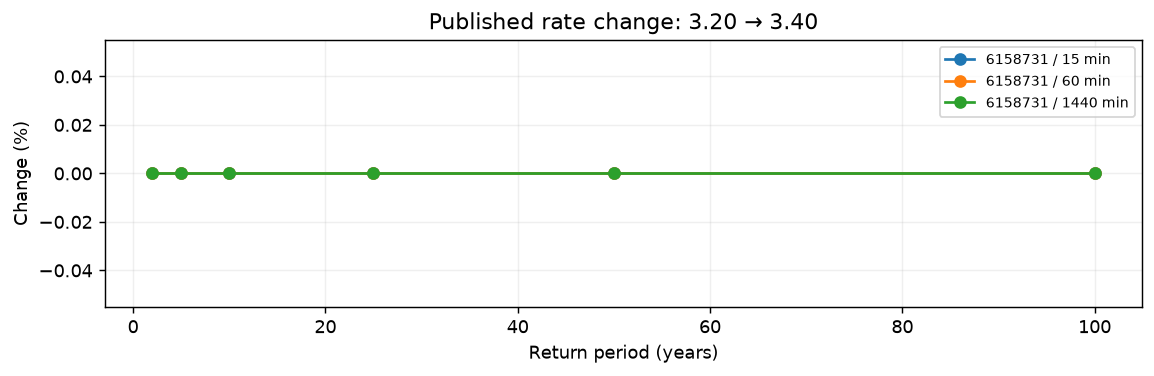

In [7]:
changes = pq.read_table(OUTPUT / "release_changes.parquet").to_pandas()
display(changes)
change_fig = go.Figure()
for duration in DURATIONS:
    view = changes[changes.duration_minutes == {"15min": 15, "1h": 60, "24h": 1440}[duration]]
    for station in SELECTED_STATIONS:
        subset = view[view.station == station]
        change_fig.add_trace(go.Scatter(x=subset.return_period_years,
            y=subset.change_percent, mode="lines+markers", name=f"{station} / {duration}"))
change_fig.update_layout(title=f"Published rate change: {PREVIOUS} → {VERSION}",
    xaxis_title="Return period (years)", yaxis_title="Change (%)", height=420)
preview, axis = plt.subplots(figsize=(9, 3))
for (station, duration), view in changes.groupby(["station", "duration_minutes"]):
    axis.plot(view.return_period_years, view.change_percent, "o-", label=f"{station} / {duration} min")
axis.set(title=f"Published rate change: {PREVIOUS} → {VERSION}", xlabel="Return period (years)", ylabel="Change (%)")
axis.grid(alpha=0.2)
axis.legend(fontsize=8)
preview.tight_layout()
show_with_preview(change_fig, preview)

## Replay and inspect artifacts

To rerun headlessly against the local SDK:

```sh
uv run --no-sync python pipelines/eccc_idf_pipeline.py --compare-version 3.20
uv run --no-sync python pipelines/eccc_idf_pipeline.py --compare-version 3.20 --cache-mode offline
```

For a union of boxes within Ontario, repeat `--bounds` instead of supplying `--stations`. This runs the same `.for_areas(...)` selection as the notebook:

```sh
uv run --no-sync python pipelines/eccc_idf_pipeline.py --province ON \
  --bounds -79.65 43.65 -79.61 43.70 --bounds -75.70 45.30 -75.65 45.35
```

`published_source_curves.parquet` preserves official rates, return-period labels, confidence half-widths, coordinates, record windows and source checksums. `rainfall_rates.parquet` contains fitted values and residuals. `release_changes.parquet` audits matching labels across releases. The cache manifest retains exact archive member paths, retrieval dates, HTTP validators and SHA-256 checksums. Derived canonical files carry source attribution, annual-exceedance semantics and the explicit probability convention.

Source: [ECCC Engineering Climate Datasets](https://climate.weather.gc.ca/prods_servs/engineering_e.html). Contains information licensed under the [Open Government Licence – Canada](https://open.canada.ca/en/open-government-licence-canada). Fitted outputs are derived from ECCC IDF.